# Marine Life Age Prediction 🐚

## Objective
The objective of this project is to estimate the age of abalone using physical measurements such as length, diameter, height, and weight.

The dataset contains 4,177 observations and 9 columns. `Rings` is used as the target variable. In this dataset, ring count is a commonly used age proxy; age in years is often approximated from the number of rings, but this project predicts the recorded ring count directly.

# Part 1 – Linear Regression

We will follow the same regression workflow used in the classroom project: data quality checks, concise exploratory data analysis, feature preparation, OLS, Linear Regression, regression diagnostics, and regularized models (Ridge, Lasso, and ElasticNet).

### Step 0: Import libraries

We import the core libraries used for data handling and the small set of visualizations required for this project. Model-specific libraries will be imported in the sections where they are first needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## Setup (reproducibility)

We set a random seed so that the train-test split and cross-validation folds are reproducible.

In [2]:
np.random.seed(57)

### Step 1: Load the dataset

Load the Abalone CSV file into a Pandas DataFrame and inspect the first five rows.

In [3]:
df = pd.read_csv(r"C:\PGA ALL\ML\assignment\marine\abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


### Step 1.1: Check the shape of the DataFrame

The shape reports the number of observations and columns.

In [4]:
df.shape

(4177, 9)

### Step 1.2: Summary statistics

We review numerical summaries to understand the ranges and spread of the measurements.

In [5]:
df.describe()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


### Step 2: Data quality checks (missing values)

We check the count and percentage of missing values in each column before deciding whether any treatment is needed.

In [6]:
def null_count_percent(data):
    nulls = data.isnull().sum()
    nulls = nulls[nulls > 0]
    return pd.DataFrame({
        "Feature": nulls.index,
        "Count_Null": nulls.values,
        "Percent_Null": nulls.values / len(data) * 100
    }).sort_values("Percent_Null", ascending=False)

nv_df = null_count_percent(df)
if nv_df.empty:
    print("No missing values found.")
else:
    display(nv_df)

No missing values found.


### Step 3: Duplicate check

Exact duplicate rows can over-represent repeated observations. We count them before deciding whether removal is appropriate.

In [7]:
df.duplicated().sum()

np.int64(0)

### Step 4: Handle missing values and check unusual measurements

This dataset typically has no missing values. We do not fill values unnecessarily. We also inspect zero values in `Height`, since a zero height is physically unusual and should be investigated rather than silently replaced.

In [8]:
print("Missing values by column:")
display(df.isnull().sum())
print("Rows with Height == 0:", (df["Height"] == 0).sum())

Missing values by column:


Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

Rows with Height == 0: 2


If missing values are present, the following code fills numerical columns with their median and categorical columns with their mode. It leaves the data unchanged when no missing values exist. Zero-height rows are retained for now and are not changed without a justified rule.

In [9]:
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


### Step 5: Check data types

`Sex` is categorical, while the measurements and `Rings` are numerical. We will encode `Sex` during feature engineering.

In [10]:
df.dtypes

Sex                object
Length            float64
Diameter          float64
Height            float64
Whole_weight      float64
Shucked_weight    float64
Viscera_weight    float64
Shell_weight      float64
Rings               int64
dtype: object

### Step 6: Summary statistics (sanity check)

We review the numerical summaries again after the data quality checks.

In [11]:
df.describe()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


### Step 7: Save a cleaned copy

Save the checked dataset to a separate file so the original CSV remains unchanged.

In [12]:
df.to_csv("abalone_cleaned.csv", index=False)

## Exploratory Data Analysis (EDA)

We will keep EDA focused and readable. The selected plots are: one countplot for `Sex`, one combined distribution plot for the target and key measurements, one relationship plot for the strongest size/weight pattern, and a correlation heatmap.

### Step 8: Univariate analysis (categorical)

A countplot shows the number of observations in each sex category.

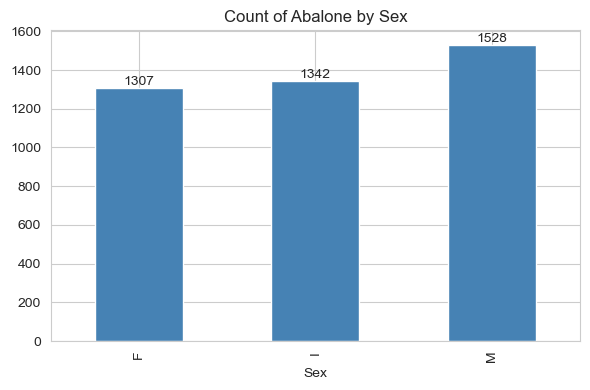

In [13]:
plt.figure(figsize=(6, 4))
counts = df["Sex"].value_counts().sort_index()
ax = counts.plot(kind="bar", color="steelblue")
ax.set_xlabel("Sex")
ax.bar_label(ax.containers[0])
plt.title("Count of Abalone by Sex")
plt.tight_layout()
plt.show()

### Step 9: Distribution of the target and selected numerical features

We plot a compact set of histograms to see the shape and spread of the target and representative measurements.

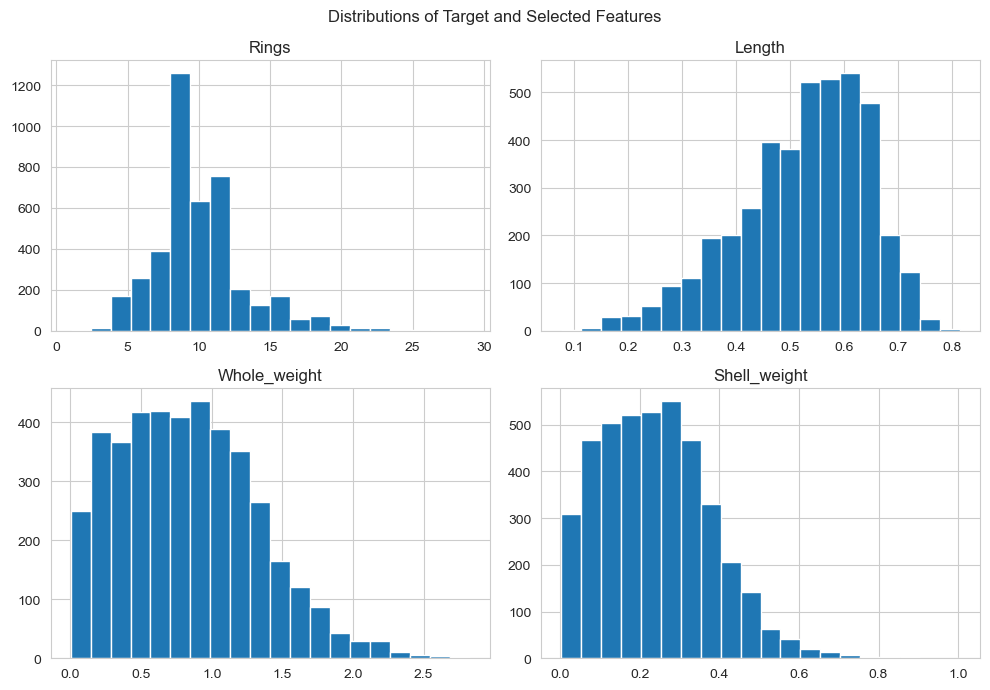

In [14]:
cols_to_plot = ["Rings", "Length", "Whole_weight", "Shell_weight"]
df[cols_to_plot].hist(figsize=(10, 7), bins=20, edgecolor="white")
plt.suptitle("Distributions of Target and Selected Features")
plt.tight_layout()
plt.show()

### Step 10: Bivariate analysis (features vs target)

The scatterplot shows how ring count varies with whole weight. It provides a first look at the relationship between a physical measurement and the target.

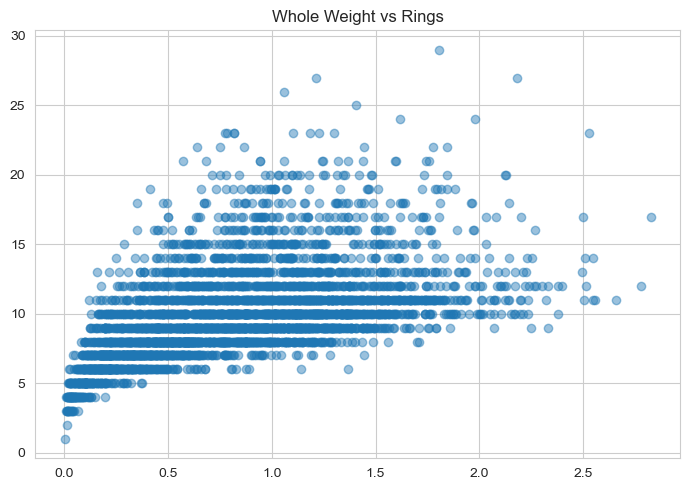

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Whole_weight"], df["Rings"], alpha=0.45)
plt.title("Whole Weight vs Rings")
plt.tight_layout()
plt.show()

### Step 11: Correlation analysis

The correlation heatmap summarises linear relationships among the numerical variables. We keep the labels compact to avoid a crowded figure.

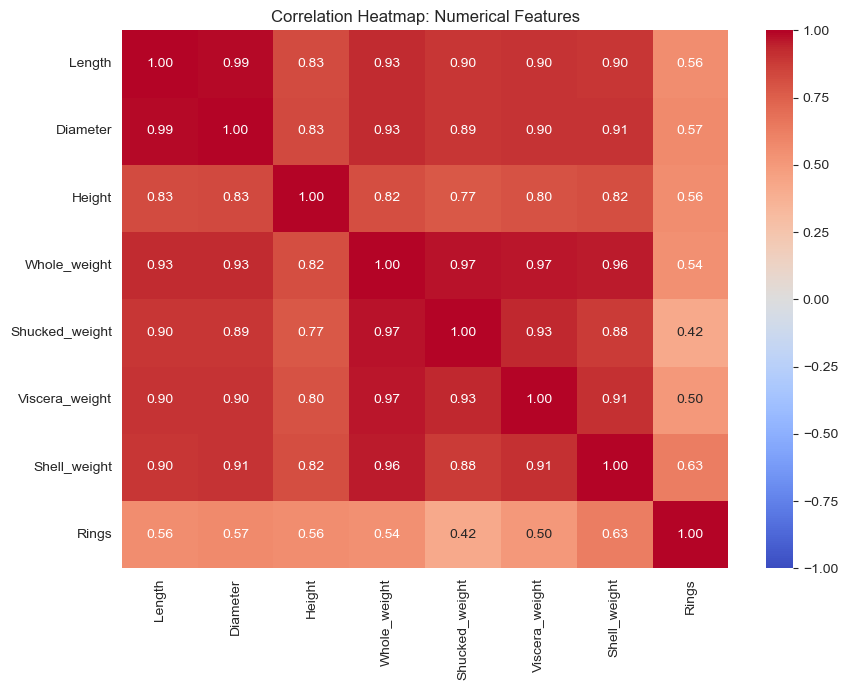

,Correlation with Rings
Shell_weight,0.627574
Diameter,0.574660
Height,0.557467
Length,0.556720
Whole_weight,0.540390
Viscera_weight,0.503819
Shucked_weight,0.420884


In [16]:
numeric_cols = df.select_dtypes(include=np.number).columns
corr = df[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title("Correlation Heatmap: Numerical Features")
plt.tight_layout()
plt.show()

corr["Rings"].drop("Rings").sort_values(key=abs, ascending=False).to_frame("Correlation with Rings")

## Feature Engineering

`Rings` is the target variable. `Sex` is categorical and will be one-hot encoded. We use `drop_first=True` to avoid a redundant dummy column in the OLS model.

In [17]:
cat_cols = ["Sex"]
target = "Rings"

df_model = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
X = df_model.drop(columns=[target])
y = df_model[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Feature matrix shape: (4177, 9)
Target shape: (4177,)


,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,1,0


## Baseline statistical model (OLS)

OLS provides a statistical summary of the relationship between the prepared features and ring count. We use the encoded feature matrix and add a constant for the intercept.

In [18]:
import statsmodels.api as sm

X_ols = sm.add_constant(X.astype(float), has_constant="add")
ols_model = sm.OLS(y.astype(float), X_ols).fit()
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Rings   R-squared:                       0.538
Model:                            OLS   Adj. R-squared:                  0.537
Method:                 Least Squares   F-statistic:                     538.9
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:01:57   Log-Likelihood:                -9204.1
No. Observations:                4177   AIC:                         1.843e+04
Df Residuals:                    4167   BIC:                         1.849e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              3.8946      0.292     13.358      0.000       3.323       4.466
Length            -0.4583      1.809     -0.253      0.800      -4.005       3.089
Diameter          11.0751      2.227      4.972      0.000       6.708      15.442
Height            10.7615      1.536      7.005      0.000       7.750      13.773
Whole_weight       8.9754      0.725     12.373      0.000       7.553      10.398
Shucked_weight   -19.7869      0.817    -24.209      0.000     -21.389     -18.184
Viscera_weight   -10.5818      1.294     -8.179      0.000     -13.118      -8.045
Shell_weight       8.7418      1.125      7.772      0.000       6.537      10.947
Sex_I             -0.8249      0.102     -8.056      0.000      -1.026      -0.624
Sex_M              0.0577      0.083      0.692      0.489      -0.106       0.221
==============================================================================
Omnibus:                      947.032   Durbin-Watson:                   1.436
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2710.271
Skew:                           1.181   Prob(JB):                         0.00
Kurtosis:                       6.162   Cond. No.                         137.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Compare R² and Adjusted R²

Adjusted R² accounts for the number of predictors included in the model.

In [19]:
print("OLS R²:", ols_model.rsquared)
print("OLS Adjusted R²:", ols_model.rsquared_adj)

OLS R²: 0.5378844030211949
OLS Adjusted R²: 0.5368863131789081


### Split data into train and test

We hold out 30% of the data for final evaluation. The test set is not used to fit the models.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=57
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (2923, 9) | X_test: (1254, 9)
y_train: (2923,) | y_test: (1254,)


## Baseline ML model (Linear Regression)

We train a baseline Linear Regression model, predict ring counts for the test set, and evaluate performance using MAE, RMSE, and R².

### Metric helper

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def eval_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"Test R²: {r2:.3f}")
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

### Train the baseline Linear Regression model

In [22]:
from sklearn.linear_model import LinearRegression

lr1 = LinearRegression()
lr1.fit(X_train, y_train)

LinearRegression()

### Make predictions on the test set

In [23]:
y_pred_lr = lr1.predict(X_test)
baseline_metrics = eval_model(y_test, y_pred_lr)

MAE: 1.620
RMSE: 2.266
Test R²: 0.509


### Quick overfitting check

Compare training and test R². A large gap may indicate that the model fits the training data much better than unseen data.

In [24]:
print("Train R²:", round(lr1.score(X_train, y_train), 3))
print("Test R²:", round(lr1.score(X_test, y_test), 3))

Train R²: 0.544
Test R²: 0.509


### Coefficients and intercept

Coefficients indicate the direction and size of each feature's linear association with predicted ring count, holding the other features constant.

In [25]:
coef_df = pd.DataFrame({"Feature": X_train.columns, "Coefficient": lr1.coef_})
coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()
display(coef_df.sort_values("Absolute_Coefficient", ascending=False).drop(columns="Absolute_Coefficient"))
print("Intercept:", lr1.intercept_)

,Feature,Coefficient
2,Height,20.160466
4,Shucked_weight,-19.202347
5,Viscera_weight,-11.556630
3,Whole_weight,8.923441
1,Diameter,8.250549
6,Shell_weight,7.643263
7,Sex_I,-0.735347
0,Length,0.324100
8,Sex_M,0.076652


Intercept: 3.573212336724855


### Compare actual and predicted values

A small sample lets us inspect predictions without printing the entire test set.

In [26]:
comparison = pd.DataFrame({"Actual_Rings": y_test, "Predicted_Rings": y_pred_lr})
comparison.head(10)

,Actual_Rings,Predicted_Rings
2541,9,10.323600
178,4,5.014277
1901,10,9.958903
1792,9,10.729514
671,17,11.136304
3566,9,11.187255
3182,10,15.637293
511,10,9.383848
2464,11,10.836437
2059,8,7.730306


## Regression assumption checks

These diagnostics help us assess whether a simple linear model is appropriate. They are diagnostic clues, not automatic pass/fail rules.

### 1. Linearity check

We compare the target with the numerical feature most strongly correlated with it.

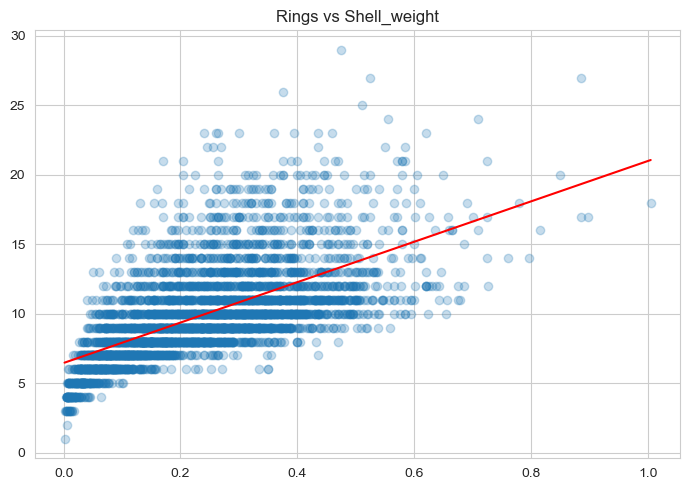

Feature selected by absolute correlation: Shell_weight


In [27]:
top_numeric_feature = corr["Rings"].drop("Rings").abs().idxmax()
plt.figure(figsize=(7, 5))
plt.scatter(df[top_numeric_feature], df["Rings"], alpha=0.25)
m, b = np.polyfit(df[top_numeric_feature], df["Rings"], 1)
x_line = np.linspace(df[top_numeric_feature].min(), df[top_numeric_feature].max(), 100)
plt.plot(x_line, m * x_line + b, color="red")
plt.title(f"Rings vs {top_numeric_feature}")
plt.tight_layout()
plt.show()
print("Feature selected by absolute correlation:", top_numeric_feature)

### 2. Multicollinearity check (VIF)

Variance Inflation Factor measures how strongly a predictor can be explained by the other predictors. High values can make individual coefficients unstable.

In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X_train.astype(float), has_constant="add")
vif_df = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_df.sort_values("VIF", ascending=False)

,Feature,VIF
4,Whole_weight,110.283604
0,const,75.561960
2,Diameter,41.490609
1,Length,39.943546
5,Shucked_weight,28.099530
7,Shell_weight,21.473905
6,Viscera_weight,17.657772
3,Height,5.846813
8,Sex_I,2.005479
9,Sex_M,1.420185


### 3. Homoscedasticity check (residuals vs predicted)

A roughly even vertical spread around zero is consistent with constant residual variance. Patterns or a funnel shape may indicate heteroscedasticity.

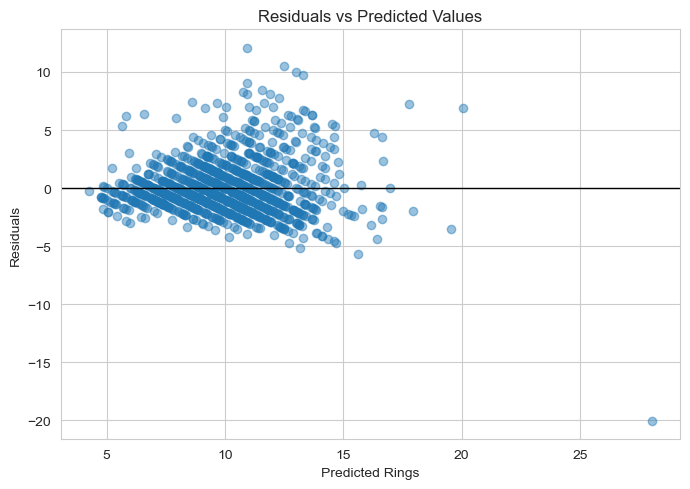

In [29]:
residuals = y_test - y_pred_lr
plt.figure(figsize=(7, 5))
plt.scatter(y_pred_lr, residuals, alpha=0.45)
plt.axhline(0, color="black", linewidth=1)
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Rings")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

We also apply the Breusch–Pagan test. A small p-value (commonly below 0.05) provides evidence against constant residual variance.

In [30]:
from statsmodels.stats.diagnostic import het_breuschpagan

X_train_sm = sm.add_constant(X_train.astype(float), has_constant="add")
ols_train = sm.OLS(y_train.astype(float), X_train_sm).fit()
bp_stat, bp_pvalue, _, _ = het_breuschpagan(ols_train.resid, ols_train.model.exog)
print("Breusch-Pagan p-value:", bp_pvalue)

Breusch-Pagan p-value: 1.4408697031987082e-58


### 4. Normality of residuals (visual)

The histogram provides a quick view of residual shape. Residual normality is mainly relevant for classical OLS inference, rather than being a requirement for predictions to exist.

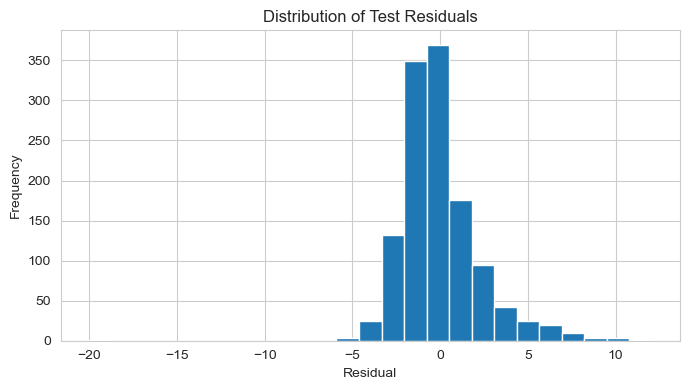

In [31]:
plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=25, edgecolor="white")
plt.title("Distribution of Test Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Regularized Regression

Ridge, Lasso, and ElasticNet penalize large coefficients to help manage multicollinearity and reduce overfitting. Since these penalties depend on feature scale, we standardize predictors using training data only.

### Step 1: Scale features

Fit the scaler on the training set only, then apply it to both training and test features to avoid data leakage.

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

### Step 2: Train Ridge, Lasso, and ElasticNet (initial settings)

In [33]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

def get_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

initial_results = []
initial_results.append({"Model": "Linear Regression", **get_metrics(y_test, lr1.predict(X_test))})

ridge_basic = Ridge(alpha=1.0).fit(X_train_scaled, y_train)
initial_results.append({"Model": "Ridge (alpha=1)", **get_metrics(y_test, ridge_basic.predict(X_test_scaled))})

lasso_basic = Lasso(alpha=0.01, max_iter=20000).fit(X_train_scaled, y_train)
initial_results.append({"Model": "Lasso (alpha=0.01)", **get_metrics(y_test, lasso_basic.predict(X_test_scaled))})

enet_basic = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000).fit(X_train_scaled, y_train)
initial_results.append({"Model": "ElasticNet (alpha=0.01)", **get_metrics(y_test, enet_basic.predict(X_test_scaled))})

pd.DataFrame(initial_results).sort_values("RMSE")

,Model,MAE,RMSE,R2
0,Linear Regression,1.620347,2.265589,0.508772
1,Ridge (alpha=1),1.620503,2.266104,0.508549
2,Lasso (alpha=0.01),1.622708,2.270484,0.506647
3,ElasticNet (alpha=0.01),1.626065,2.282410,0.501451


### Step 3: K-Fold cross-validation

K-Fold cross-validation repeatedly trains and validates a model on different portions of the training data. We compare mean RMSE across folds; lower RMSE indicates better average prediction accuracy.

In [34]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=57)

def cv_rmse(model, X_data, y_data):
    scores = cross_val_score(
        model, X_data, y_data, cv=kf,
        scoring="neg_root_mean_squared_error"
    )
    return -scores.mean(), scores.std()

### Step 4: Tune Ridge (alpha) with K-Fold

In [35]:
ridge_cv_results = []
for alpha in [0.01, 0.1, 1, 10, 100]:
    mean_rmse, std_rmse = cv_rmse(Ridge(alpha=alpha), X_train_scaled, y_train)
    ridge_cv_results.append({"Model": "Ridge", "alpha": alpha,
                             "RMSE_Mean": mean_rmse, "RMSE_Std": std_rmse})
ridge_cv_df = pd.DataFrame(ridge_cv_results).sort_values("RMSE_Mean")
ridge_cv_df

,Model,alpha,RMSE_Mean,RMSE_Std
2,Ridge,1.00,2.184139,0.072158
1,Ridge,0.10,2.184250,0.071744
0,Ridge,0.01,2.184278,0.071702
3,Ridge,10.00,2.189526,0.074974
4,Ridge,100.00,2.236254,0.078647


### Step 5: Tune Lasso (alpha) with K-Fold

In [36]:
lasso_cv_results = []
for alpha in [0.0001, 0.001, 0.01, 0.1, 1]:
    mean_rmse, std_rmse = cv_rmse(Lasso(alpha=alpha, max_iter=20000), X_train_scaled, y_train)
    lasso_cv_results.append({"Model": "Lasso", "alpha": alpha,
                             "RMSE_Mean": mean_rmse, "RMSE_Std": std_rmse})
lasso_cv_df = pd.DataFrame(lasso_cv_results).sort_values("RMSE_Mean")
lasso_cv_df

,Model,alpha,RMSE_Mean,RMSE_Std
1,Lasso,0.0010,2.183997,0.072045
0,Lasso,0.0001,2.184247,0.071732
2,Lasso,0.0100,2.187863,0.074967
3,Lasso,0.1000,2.271621,0.080874
4,Lasso,1.0000,2.687924,0.090256


### Step 6: Tune ElasticNet (alpha and l1_ratio) with K-Fold

In [37]:
enet_cv_results = []
for alpha in [0.001, 0.01, 0.1, 1]:
    for l1_ratio in [0.1, 0.5, 0.9]:
        mean_rmse, std_rmse = cv_rmse(
            ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=20000),
            X_train_scaled, y_train
        )
        enet_cv_results.append({"Model": "ElasticNet", "alpha": alpha,
                                "l1_ratio": l1_ratio, "RMSE_Mean": mean_rmse,
                                "RMSE_Std": std_rmse})
enet_cv_df = pd.DataFrame(enet_cv_results).sort_values("RMSE_Mean")
enet_cv_df

,Model,alpha,l1_ratio,RMSE_Mean,RMSE_Std
2,ElasticNet,0.001,0.9,2.183994,0.072120
1,ElasticNet,0.001,0.5,2.184093,0.072406
0,ElasticNet,0.001,0.1,2.184327,0.072667
5,ElasticNet,0.010,0.9,2.189493,0.075409
4,ElasticNet,0.010,0.5,2.194799,0.076286
3,ElasticNet,0.010,0.1,2.198463,0.076619
8,ElasticNet,0.100,0.9,2.273938,0.080442
7,ElasticNet,0.100,0.5,2.284135,0.079851
6,ElasticNet,0.100,0.1,2.288466,0.080219
9,ElasticNet,1.000,0.1,2.558493,0.089382


### Step 7: Compare the best configuration from each model

In [38]:
best_ridge = ridge_cv_df.iloc[0]
best_lasso = lasso_cv_df.iloc[0]
best_enet = enet_cv_df.iloc[0]

best_cv_comparison = pd.DataFrame([
    {"Model": "Ridge", "alpha": best_ridge["alpha"], "l1_ratio": np.nan,
     "CV_RMSE": best_ridge["RMSE_Mean"], "CV_RMSE_Std": best_ridge["RMSE_Std"]},
    {"Model": "Lasso", "alpha": best_lasso["alpha"], "l1_ratio": np.nan,
     "CV_RMSE": best_lasso["RMSE_Mean"], "CV_RMSE_Std": best_lasso["RMSE_Std"]},
    {"Model": "ElasticNet", "alpha": best_enet["alpha"], "l1_ratio": best_enet["l1_ratio"],
     "CV_RMSE": best_enet["RMSE_Mean"], "CV_RMSE_Std": best_enet["RMSE_Std"]}
]).sort_values("CV_RMSE")
best_cv_comparison

,Model,alpha,l1_ratio,CV_RMSE,CV_RMSE_Std
2,ElasticNet,0.001,0.9,2.183994,0.072120
1,Lasso,0.001,NaN,2.183997,0.072045
0,Ridge,1.000,NaN,2.184139,0.072158


### Step 8: Evaluate tuned models on the test set

The test set is used here only for final comparison after choosing hyperparameters using cross-validation on the training data.

In [39]:
ridge_final = Ridge(alpha=float(best_ridge["alpha"])).fit(X_train_scaled, y_train)
lasso_final = Lasso(alpha=float(best_lasso["alpha"]), max_iter=20000).fit(X_train_scaled, y_train)
enet_final = ElasticNet(alpha=float(best_enet["alpha"]),
                        l1_ratio=float(best_enet["l1_ratio"]),
                        max_iter=20000).fit(X_train_scaled, y_train)

final_results = [
    {"Model": "Linear Regression", **get_metrics(y_test, lr1.predict(X_test))},
    {"Model": "Ridge (tuned)", **get_metrics(y_test, ridge_final.predict(X_test_scaled))},
    {"Model": "Lasso (tuned)", **get_metrics(y_test, lasso_final.predict(X_test_scaled))},
    {"Model": "ElasticNet (tuned)", **get_metrics(y_test, enet_final.predict(X_test_scaled))}
]
results_df = pd.DataFrame(final_results).sort_values("RMSE")
results_df

,Model,MAE,RMSE,R2
0,Linear Regression,1.620347,2.265589,0.508772
2,Lasso (tuned),1.620424,2.265665,0.508739
3,ElasticNet (tuned),1.620471,2.265818,0.508673
1,Ridge (tuned),1.620503,2.266104,0.508549


### Step 9: Coefficient inspection

Compare standardized coefficients to see how regularization changes coefficient size. Coefficients are on the standardized-feature scale, so their magnitudes can be compared across predictors.

In [40]:
lr_scaled = LinearRegression().fit(X_train_scaled, y_train)
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "LinearRegression": lr_scaled.coef_,
    "Ridge": ridge_final.coef_,
    "Lasso": lasso_final.coef_,
    "ElasticNet": enet_final.coef_
})
coef_df

,Feature,LinearRegression,Ridge,Lasso,ElasticNet
0,Length,0.038843,0.044131,0.029648,0.032189
1,Diameter,0.816932,0.808891,0.819042,0.816403
2,Height,0.797638,0.798996,0.797276,0.797712
3,Whole_weight,4.411557,4.191886,4.267701,4.217490
4,Shucked_weight,-4.295251,-4.192924,-4.228980,-4.205526
5,Viscera_weight,-1.270385,-1.218887,-1.224423,-1.213891
6,Shell_weight,1.076268,1.149396,1.119425,1.136634
7,Sex_I,-0.344888,-0.346793,-0.345266,-0.345790
8,Sex_M,0.036997,0.036330,0.035854,0.035772


## Final Conclusion

Summarise the test-set metrics and identify the model with the lowest test RMSE. Discuss the most useful predictors cautiously: this dataset supports prediction and association analysis, not proof of cause and effect.

In [41]:
best_test_model = results_df.iloc[0]
print("Best model by test RMSE:", best_test_model["Model"])
print(f"Test MAE: {best_test_model['MAE']:.3f}")
print(f"Test RMSE: {best_test_model['RMSE']:.3f}")
print(f"Test R²: {best_test_model['R2']:.3f}")

Best model by test RMSE: Linear Regression
Test MAE: 1.620
Test RMSE: 2.266
Test R²: 0.509


### Conclusion

This project used physical measurements of shellfish to predict their age using ring count as an indicator. Linear Regression was compared with Ridge, Lasso, and ElasticNet Regression using MAE, RMSE, and R². Cross-validation and hyperparameter tuning were used to evaluate model performance, while residual analysis and multicollinearity diagnostics helped identify potential limitations. The best-performing model was selected based on the evaluation results. Since ring count is used as a proxy for age, predictions may be less accurate for unusual observations.